# Tugas 2 - Klasifikasi Gambar Pakaian dengan Convolutional Neural Network (PyTorch)

| Nama | NRP |
|------|-----|
| Rayhan Lutfi Hakim | 5054251043 |
https://riyoshi1--fashion-mnist.us-east.modal.run/

## Deskripsi Tugas
Pada tugas ini, kita akan menggunakan Fashion-MNIST Dataset. Dataset bisa diakses melalui link berikut:\
https://www.kaggle.com/datasets/zalando-research/fashionmnist

Dataset berisi 70.000 gambar grayscale berukuran 28×28 piksel yang terbagi ke dalam 10 kelas pakaian (T-shirt/top, Trouser, Pullover, Dress, Coat, Sandal, Shirt, Sneaker, Bag, Ankle boot). Tujuan utama dari tugas ini adalah membangun model Convolutional Neural Network (CNN) menggunakan **PyTorch** untuk mengklasifikasikan jenis pakaian, lalu membandingkannya dengan ANN biasa.

Disarankan menggunakan GPU (Google Colab: *Runtime → Change runtime type → T4 GPU*, atau Kaggle Notebook).

Langkah-langkah yang harus dilakukan antara lain:
1. Persiapan Dataset dan Eksplorasi Awal
   - Memuat dataset, melihat contoh gambar, dan distribusi label.
2. Preprocessing
   - Memproses data gambar agar siap digunakan oleh model.
3. Eksperimen Model
   - Bangun model ANN, CNN sederhana, dan CNN dengan Batch Normalization dan Dropout.
4. Evaluasi Model
   - Hitung metrik evaluasi, visualisasikan hasilnya, dan simpan model terbaik.
5. Analisis dan Kesimpulan
   - Bandingkan hasil ketiga model dan berikan kesimpulan.

# 1. Persiapan Dataset dan Eksplorasi Awal

In [2]:
# Import library yang dibutuhkan (pandas, numpy, matplotlib, seaborn, sklearn, torch, dll).
# Set random seed dengan torch.manual_seed(42) dan np.random.seed(42).
# Tentukan device: device = "cuda" if torch.cuda.is_available() else "cpu", lalu tampilkan device yang digunakan.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report
import warnings

warnings.filterwarnings("ignore")
torch.manual_seed(42)
np.random.seed(42)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

Device: cuda


In [3]:
# Load file fashion-mnist_train.csv dan fashion-mnist_test.csv.
# Setiap baris berisi 1 kolom label dan 784 kolom piksel (28×28) bernilai 0-255.
# Tampilkan ukuran data train dan test.
train_df = pd.read_csv("fashion-mnist_train.csv")
test_df = pd.read_csv("fashion-mnist_test.csv")
print("Ukuran train:", train_df.shape)
print("Ukuran test:", test_df.shape)

Ukuran train: (60000, 785)
Ukuran test: (10000, 785)


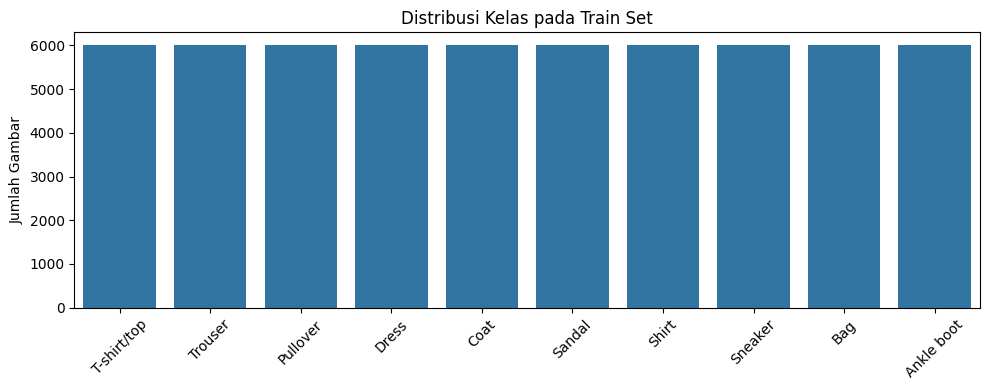

In [4]:
# Buat list atau dictionary yang memetakan label angka (0-9) ke nama kelas.
# Tampilkan distribusi kelas pada train set dalam bentuk bar plot.
class_names = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]
label_counts = train_df["label"].value_counts().sort_index()
plt.figure(figsize=(10, 4))
sns.barplot(x=[class_names[i] for i in label_counts.index], y=label_counts.values)
plt.xticks(rotation=45)
plt.ylabel("Jumlah Gambar")
plt.title("Distribusi Kelas pada Train Set")
plt.tight_layout()
plt.show()

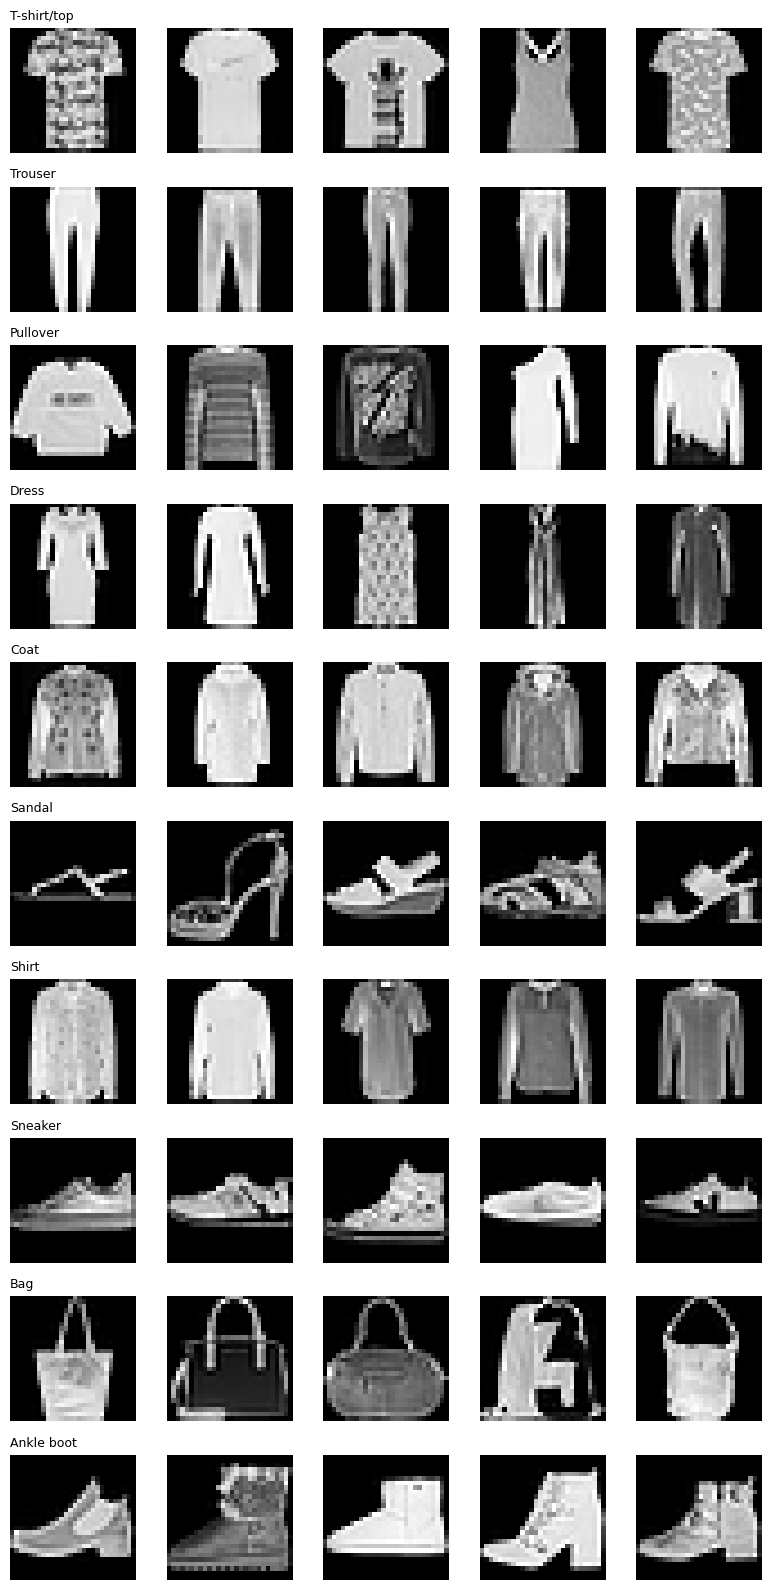

In [5]:
# Tampilkan contoh gambar dari setiap kelas (misalnya grid 10 kelas × 5 gambar) beserta nama kelasnya.
# Kelas mana saja yang secara visual terlihat mirip?
fig, axes = plt.subplots(10, 5, figsize=(8, 16))
for c in range(10):
    samples = train_df[train_df["label"] == c].drop(columns="label").values[:5]
    for j in range(5):
        axes[c, j].imshow(samples[j].reshape(28, 28), cmap="gray")
        axes[c, j].axis("off")
        if j == 0:
            axes[c, j].set_title(class_names[c], fontsize=9, loc="left")
plt.tight_layout()
plt.show()

## Lakukan Exploratory Data Analysis (EDA) tambahan yang diperlukan.

# 2. Preprocessing

Model yang berbeda membutuhkan bentuk input yang berbeda. Di PyTorch, urutan dimensi gambar adalah **(batch, channel, tinggi, lebar)**:

| Model | Bentuk input |
|---|---|
| ANN | `(N, 784)`, atau `(N, 1, 28, 28)` dengan `nn.Flatten()` di awal model |
| CNN | `(N, 1, 28, 28)` |

In [6]:
# Pisahkan label (y) dan piksel (X) untuk data train dan test.
y_train_full = train_df["label"].values
X_train_full = train_df.drop(columns="label").values
y_test_np = test_df["label"].values
X_test_np = test_df.drop(columns="label").values

In [7]:
# Normalisasi nilai piksel ke rentang 0-1 (bagi dengan 255).
X_train_full = X_train_full.astype(np.float32) / 255.0
X_test_np = X_test_np.astype(np.float32) / 255.0
print(X_train_full.min(), X_train_full.max())

0.0 1.0


In [8]:
# Bagi data train menjadi train set dan validation set (misalnya 90:10) dengan stratify=y.
# Test set dari file fashion-mnist_test.csv hanya digunakan untuk evaluasi akhir.
X_tr, X_va, y_tr, y_va = train_test_split(X_train_full, y_train_full, test_size=0.1, stratify=y_train_full, random_state=42)
print("Train:", X_tr.shape, "Validation:", X_va.shape, "Test:", X_test_np.shape)

Train: (54000, 784) Validation: (6000, 784) Test: (10000, 784)


In [9]:
# Ubah data menjadi tensor: X bertipe torch.float32 dengan bentuk (N, 1, 28, 28), y bertipe torch.long (wajib untuk nn.CrossEntropyLoss).
# Buat DataLoader untuk train, validation, dan test menggunakan TensorDataset (shuffle=True hanya untuk train).
def make_tensors(X_arr, y_arr):
    X_t = torch.tensor(X_arr.reshape(-1, 1, 28, 28), dtype=torch.float32)
    y_t = torch.tensor(y_arr, dtype=torch.long)
    return X_t, y_t

X_tr_t, y_tr_t = make_tensors(X_tr, y_tr)
X_va_t, y_va_t = make_tensors(X_va, y_va)
X_te_t, y_te_t = make_tensors(X_test_np, y_test_np)

BATCH_SIZE = 128
train_loader = DataLoader(TensorDataset(X_tr_t, y_tr_t), batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(TensorDataset(X_va_t, y_va_t), batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(TensorDataset(X_te_t, y_te_t), batch_size=BATCH_SIZE, shuffle=False)

# 3. Eksperimen Model

## 3.1 ANN (Baseline)

Gambar di-flatten menjadi vektor 784 nilai, lalu diproses oleh ANN biasa. Karena ini klasifikasi multikelas, gunakan **10 neuron output** tanpa Softmax dan **`nn.CrossEntropyLoss`** sebagai loss function. Loss ini sudah menyertakan Softmax di dalamnya.

Contoh arsitektur: `Flatten → Linear(784, 256) → ReLU → Linear(256, 128) → ReLU → Linear(128, 10)`

In [10]:
# Definisikan arsitektur ANN sebagai class turunan nn.Module, lalu pindahkan ke device dengan model.to(device).
# Tampilkan arsitektur model dengan print(model) dan jumlah parameternya: sum(p.numel() for p in model.parameters()).
class ANN(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 256),
            nn.ReLU(),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Linear(128, 10),
        )

    def forward(self, x):
        return self.net(x)

def count_params(model):
    return sum(p.numel() for p in model.parameters())

torch.manual_seed(42)
ann_model = ANN().to(device)
print(ann_model)
print("Jumlah parameter:", count_params(ann_model))

ANN(
  (net): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=256, bias=True)
    (2): ReLU()
    (3): Linear(in_features=256, out_features=128, bias=True)
    (4): ReLU()
    (5): Linear(in_features=128, out_features=10, bias=True)
  )
)
Jumlah parameter: 235146


In [11]:
# Tentukan loss function (nn.CrossEntropyLoss), optimizer, learning rate, jumlah epoch, dan batch size.
# Tulis training loop. Setiap batch harus dipindahkan ke device yang sama dengan model (x.to(device), y.to(device)).
# Di akhir setiap epoch, hitung loss dan accuracy train dan validation (gunakan model.eval() dan torch.no_grad()), simpan ke dictionary history.
# Disarankan membuat training loop dalam bentuk fungsi agar dapat digunakan ulang pada 3.2 dan 3.3.
def eval_loader(model, loader, criterion):
    model.eval()
    total_loss, correct, n = 0.0, 0, 0
    with torch.no_grad():
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            out = model(xb)
            total_loss += criterion(out, yb).item() * xb.size(0)
            correct += (out.argmax(dim=1) == yb).sum().item()
            n += xb.size(0)
    return total_loss / n, correct / n

def train_model(model, criterion, optimizer, epochs, train_loader, val_loader):
    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
    for epoch in range(epochs):
        model.train()
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            out = model(xb)
            loss = criterion(out, yb)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
        tr_loss, tr_acc = eval_loader(model, train_loader, criterion)
        va_loss, va_acc = eval_loader(model, val_loader, criterion)
        history["train_loss"].append(tr_loss)
        history["train_acc"].append(tr_acc)
        history["val_loss"].append(va_loss)
        history["val_acc"].append(va_acc)
        print(f"Epoch {epoch + 1}/{epochs} | train_loss {tr_loss:.4f} | train_acc {tr_acc:.4f} | val_loss {va_loss:.4f} | val_acc {va_acc:.4f}")
    return history

EPOCHS = 15
LEARNING_RATE = 0.001
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(ann_model.parameters(), lr=LEARNING_RATE)
history_ann = train_model(ann_model, criterion, optimizer, EPOCHS, train_loader, val_loader)

Epoch 1/15 | train_loss 0.4332 | train_acc 0.8452 | val_loss 0.4444 | val_acc 0.8398
Epoch 2/15 | train_loss 0.3795 | train_acc 0.8606 | val_loss 0.4122 | val_acc 0.8475
Epoch 3/15 | train_loss 0.3238 | train_acc 0.8830 | val_loss 0.3583 | val_acc 0.8708
Epoch 4/15 | train_loss 0.3047 | train_acc 0.8899 | val_loss 0.3526 | val_acc 0.8732
Epoch 5/15 | train_loss 0.2894 | train_acc 0.8950 | val_loss 0.3384 | val_acc 0.8782
Epoch 6/15 | train_loss 0.2703 | train_acc 0.8993 | val_loss 0.3285 | val_acc 0.8808
Epoch 7/15 | train_loss 0.2859 | train_acc 0.8921 | val_loss 0.3526 | val_acc 0.8717
Epoch 8/15 | train_loss 0.2572 | train_acc 0.9031 | val_loss 0.3347 | val_acc 0.8793
Epoch 9/15 | train_loss 0.2487 | train_acc 0.9068 | val_loss 0.3325 | val_acc 0.8817
Epoch 10/15 | train_loss 0.2440 | train_acc 0.9102 | val_loss 0.3309 | val_acc 0.8798
Epoch 11/15 | train_loss 0.2139 | train_acc 0.9207 | val_loss 0.3171 | val_acc 0.8880
Epoch 12/15 | train_loss 0.2184 | train_acc 0.9166 | val_loss 0

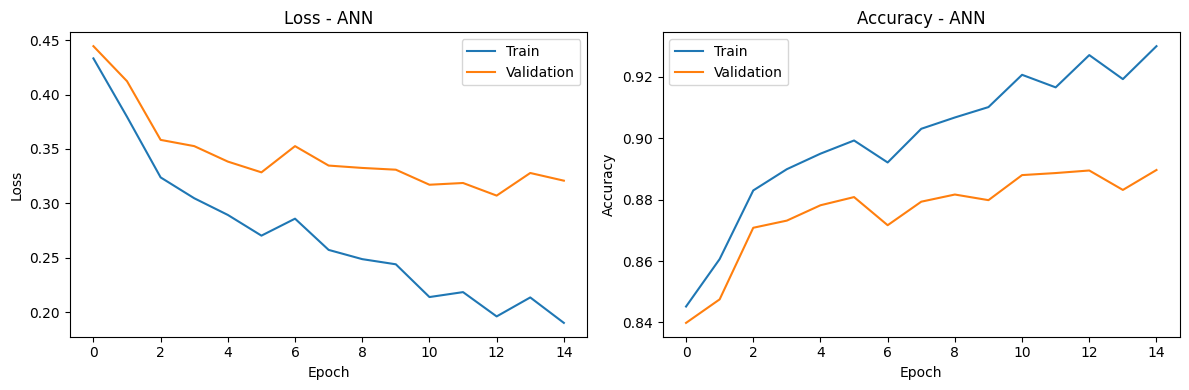

In [12]:
# Tampilkan learning curve (loss dan accuracy) train vs validation.
def plot_history(history, title):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(history["train_loss"], label="Train")
    axes[0].plot(history["val_loss"], label="Validation")
    axes[0].set_title(f"Loss - {title}")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Loss")
    axes[0].legend()
    axes[1].plot(history["train_acc"], label="Train")
    axes[1].plot(history["val_acc"], label="Validation")
    axes[1].set_title(f"Accuracy - {title}")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Accuracy")
    axes[1].legend()
    plt.tight_layout()
    plt.show()

plot_history(history_ann, "ANN")

In [13]:
# Lakukan prediksi pada test set dengan model.eval() dan torch.no_grad().
# Ambil kelas dengan nilai output terbesar menggunakan argmax(dim=1). Simpan hasil prediksi label dalam bentuk numpy array.
def predict_labels(model, loader):
    model.eval()
    preds = []
    with torch.no_grad():
        for xb, _ in loader:
            out = model(xb.to(device))
            preds.append(out.argmax(dim=1).cpu())
    return torch.cat(preds).numpy()

ann_pred = predict_labels(ann_model, test_loader)

## 3.2 CNN Sederhana

Bangun CNN dengan **2 blok konvolusi**, masing-masing terdiri dari Conv2d → ReLU → MaxPool2d, lalu dilanjutkan Flatten dan Linear.

Contoh arsitektur: `[Conv2d(1, 32, 3, padding=1) → ReLU → MaxPool2d(2)] → [Conv2d(32, 64, 3, padding=1) → ReLU → MaxPool2d(2)] → Flatten → Linear(64×7×7, 128) → ReLU → Linear(128, 10)`

In [14]:
# Definisikan arsitektur CNN sederhana sebagai class turunan nn.Module (gunakan nn.Conv2d, nn.MaxPool2d, nn.Flatten, dan nn.Linear).
# Tampilkan arsitektur model beserta jumlah parameternya.
# Hitung secara manual ukuran output setiap layer konvolusi dan pooling menggunakan rumus (W - K + 2P) / S + 1.
# Hasil perhitungan ini menentukan ukuran input nn.Linear pertama setelah Flatten (channel × tinggi × lebar).
# Cocokkan dengan mengirim satu tensor dummy torch.zeros(1, 1, 28, 28) ke bagian konvolusi dan cetak bentuk outputnya.
class SimpleCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, 128),
            nn.ReLU(),
            nn.Linear(128, 10),
        )

    def forward(self, x):
        return self.classifier(self.features(x))

torch.manual_seed(42)
cnn_model = SimpleCNN().to(device)
print(cnn_model)
print("Jumlah parameter:", count_params(cnn_model))

dummy = torch.zeros(1, 1, 28, 28).to(device)
for layer in cnn_model.features:
    dummy = layer(dummy)
    print(layer.__class__.__name__, "->", tuple(dummy.shape))

SimpleCNN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3136, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=10, bias=True)
  )
)
Jumlah parameter: 421642
Conv2d -> (1, 32, 28, 28)
ReLU -> (1, 32, 28, 28)
MaxPool2d -> (1, 32, 14, 14)
Conv2d -> (1, 64, 14, 14)
ReLU -> (1, 64, 14, 14)
MaxPool2d -> (1, 64, 7, 7)


Epoch 1/15 | train_loss 0.3920 | train_acc 0.8577 | val_loss 0.4023 | val_acc 0.8563
Epoch 2/15 | train_loss 0.2932 | train_acc 0.8949 | val_loss 0.3145 | val_acc 0.8860
Epoch 3/15 | train_loss 0.2476 | train_acc 0.9104 | val_loss 0.2761 | val_acc 0.8992
Epoch 4/15 | train_loss 0.2523 | train_acc 0.9075 | val_loss 0.2851 | val_acc 0.8950
Epoch 5/15 | train_loss 0.2183 | train_acc 0.9214 | val_loss 0.2679 | val_acc 0.9048
Epoch 6/15 | train_loss 0.2002 | train_acc 0.9269 | val_loss 0.2451 | val_acc 0.9092
Epoch 7/15 | train_loss 0.1844 | train_acc 0.9344 | val_loss 0.2445 | val_acc 0.9083
Epoch 8/15 | train_loss 0.1679 | train_acc 0.9413 | val_loss 0.2357 | val_acc 0.9102
Epoch 9/15 | train_loss 0.1555 | train_acc 0.9440 | val_loss 0.2310 | val_acc 0.9127
Epoch 10/15 | train_loss 0.1474 | train_acc 0.9460 | val_loss 0.2378 | val_acc 0.9143
Epoch 11/15 | train_loss 0.1267 | train_acc 0.9549 | val_loss 0.2287 | val_acc 0.9170
Epoch 12/15 | train_loss 0.1334 | train_acc 0.9498 | val_loss 0

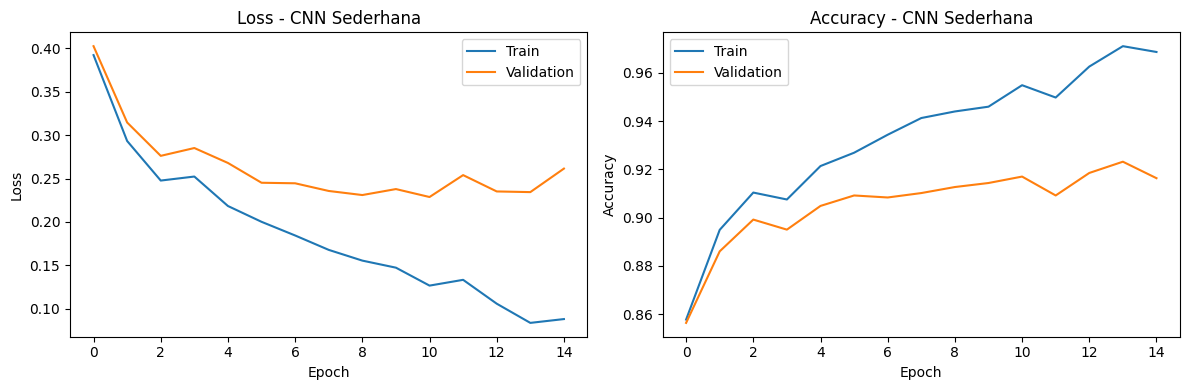

In [15]:
# Latih model dengan pengaturan yang sama seperti 3.1 agar perbandingan adil.
# Tampilkan learning curve train vs validation.
optimizer = torch.optim.Adam(cnn_model.parameters(), lr=LEARNING_RATE)
history_cnn = train_model(cnn_model, criterion, optimizer, EPOCHS, train_loader, val_loader)
plot_history(history_cnn, "CNN Sederhana")

In [16]:
# Lakukan prediksi pada test set dan simpan hasil prediksi label.
cnn_pred = predict_labels(cnn_model, test_loader)

## 3.3 CNN dengan Batch Normalization dan Dropout

Gunakan arsitektur CNN pada 3.2, lalu tambahkan **Batch Normalization** setelah setiap layer konvolusi dan **Dropout** sebelum layer output.

In [17]:
# Definisikan arsitektur CNN dengan Batch Normalization dan Dropout.
# Urutan yang umum: nn.Conv2d -> nn.BatchNorm2d(jumlah_channel_output) -> nn.ReLU -> nn.MaxPool2d.
# Tambahkan nn.Dropout(p) sebelum layer output.
# Ingat: BatchNorm dan Dropout berperilaku berbeda saat training dan evaluasi, pastikan memanggil model.train() dan model.eval() di tempat yang tepat.
# Tampilkan arsitektur model beserta jumlah parameternya.
class CNNBNDropout(nn.Module):
    def __init__(self, p=0.5):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, 128),
            nn.ReLU(),
            nn.Dropout(p),
            nn.Linear(128, 10),
        )

    def forward(self, x):
        return self.classifier(self.features(x))

torch.manual_seed(42)
cnn_bn_model = CNNBNDropout().to(device)
print(cnn_bn_model)
print("Jumlah parameter:", count_params(cnn_bn_model))

CNNBNDropout(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3136, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.5, inplace=False)
    (4): Linear(in_features=128, out_features=10, bias=True)
  )
)
Jumlah parameter: 421834


Epoch 1/15 | train_loss 0.3380 | train_acc 0.8768 | val_loss 0.3546 | val_acc 0.8717
Epoch 2/15 | train_loss 0.2687 | train_acc 0.9005 | val_loss 0.3012 | val_acc 0.8912
Epoch 3/15 | train_loss 0.2217 | train_acc 0.9177 | val_loss 0.2683 | val_acc 0.9037
Epoch 4/15 | train_loss 0.2278 | train_acc 0.9126 | val_loss 0.2822 | val_acc 0.8995
Epoch 5/15 | train_loss 0.1823 | train_acc 0.9329 | val_loss 0.2396 | val_acc 0.9137
Epoch 6/15 | train_loss 0.2006 | train_acc 0.9209 | val_loss 0.2612 | val_acc 0.9013
Epoch 7/15 | train_loss 0.1557 | train_acc 0.9412 | val_loss 0.2297 | val_acc 0.9172
Epoch 8/15 | train_loss 0.1508 | train_acc 0.9434 | val_loss 0.2311 | val_acc 0.9170
Epoch 9/15 | train_loss 0.1394 | train_acc 0.9478 | val_loss 0.2210 | val_acc 0.9212
Epoch 10/15 | train_loss 0.1423 | train_acc 0.9461 | val_loss 0.2362 | val_acc 0.9157
Epoch 11/15 | train_loss 0.1238 | train_acc 0.9539 | val_loss 0.2242 | val_acc 0.9172
Epoch 12/15 | train_loss 0.1199 | train_acc 0.9571 | val_loss 0

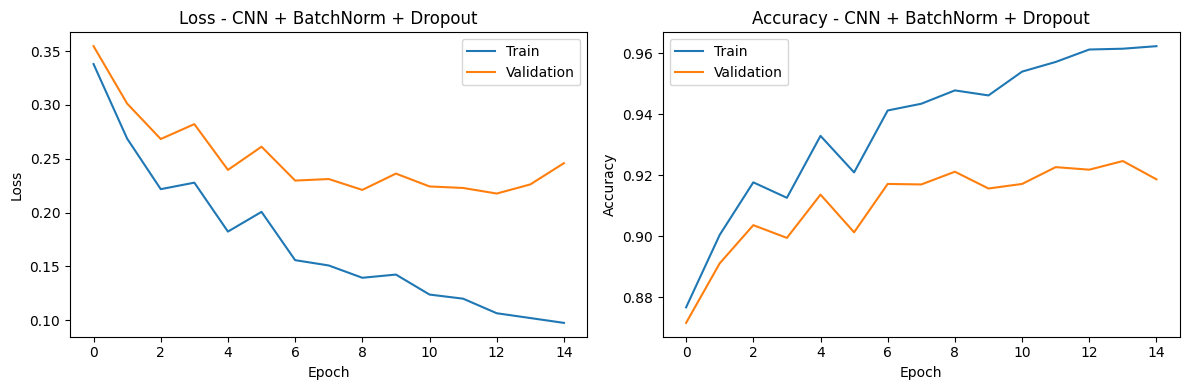

In [18]:
# Latih model dengan pengaturan yang sama seperti 3.2.
# Tampilkan learning curve train vs validation.
# Perhatikan selisih antara train dan validation dibandingkan dengan model 3.2.
optimizer = torch.optim.Adam(cnn_bn_model.parameters(), lr=LEARNING_RATE)
history_cnn_bn = train_model(cnn_bn_model, criterion, optimizer, EPOCHS, train_loader, val_loader)
plot_history(history_cnn_bn, "CNN + BatchNorm + Dropout")

In [19]:
# Lakukan prediksi pada test set dan simpan hasil prediksi label.
cnn_bn_pred = predict_labels(cnn_bn_model, test_loader)

# 4. Evaluasi Model

In [20]:
# Tampilkan metrik evaluasi untuk setiap model: Accuracy, Precision, Recall, dan F1-Score (macro average),
# beserta jumlah parameter setiap model. Sajikan dalam satu tabel perbandingan.
models_dict = {"ANN": ann_model, "CNN Sederhana": cnn_model, "CNN + BN + Dropout": cnn_bn_model}
preds_dict = {"ANN": ann_pred, "CNN Sederhana": cnn_pred, "CNN + BN + Dropout": cnn_bn_pred}

rows = []
for name, pred in preds_dict.items():
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test_np, pred),
        "Precision (macro)": precision_score(y_test_np, pred, average="macro"),
        "Recall (macro)": recall_score(y_test_np, pred, average="macro"),
        "F1-Score (macro)": f1_score(y_test_np, pred, average="macro"),
        "Jumlah Parameter": count_params(models_dict[name]),
    })
results_df = pd.DataFrame(rows).set_index("Model")
display(results_df.round(4))

best_name = results_df["Accuracy"].idxmax()
best_model = models_dict[best_name]
best_pred = preds_dict[best_name]
print("Model terbaik:", best_name)

,Accuracy,Precision (macro),Recall (macro),F1-Score (macro),Jumlah Parameter
Model,,,,,
ANN,0.8932,0.8961,0.8932,0.8940,235146
CNN Sederhana,0.9226,0.9248,0.9226,0.9231,421642
CNN + BN + Dropout,0.9250,0.9253,0.9250,0.9245,421834


Model terbaik: CNN + BN + Dropout


In [21]:
# Tampilkan classification report (metrik per kelas) untuk model terbaik.
print(f"Classification Report - {best_name}")
print(classification_report(y_test_np, best_pred, target_names=class_names, digits=4))

Classification Report - CNN + BN + Dropout
              precision    recall  f1-score   support

 T-shirt/top     0.8314    0.9220    0.8743      1000
     Trouser     0.9950    0.9890    0.9920      1000
    Pullover     0.8691    0.8960    0.8823      1000
       Dress     0.9146    0.9530    0.9334      1000
        Coat     0.9237    0.8600    0.8907      1000
      Sandal     0.9898    0.9710    0.9803      1000
       Shirt     0.8151    0.7320    0.7713      1000
     Sneaker     0.9500    0.9700    0.9599      1000
         Bag     0.9919    0.9850    0.9885      1000
  Ankle boot     0.9720    0.9720    0.9720      1000

    accuracy                         0.9250     10000
   macro avg     0.9253    0.9250    0.9245     10000
weighted avg     0.9253    0.9250    0.9245     10000



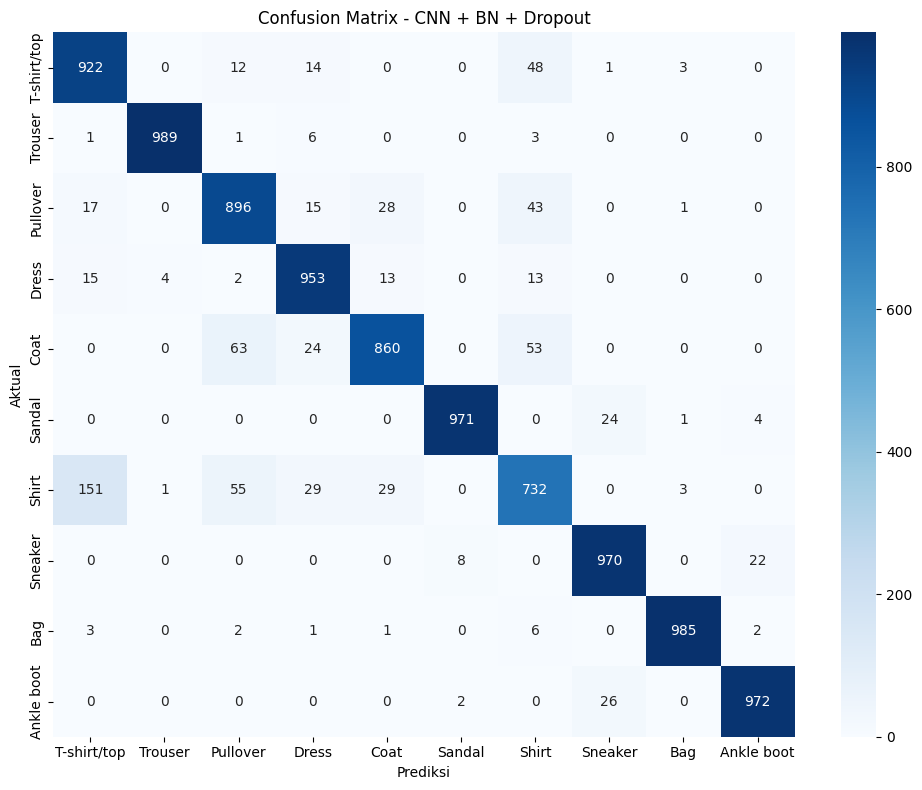

Shirt diprediksi sebagai T-shirt/top: 151 kali
Coat diprediksi sebagai Pullover: 63 kali
Shirt diprediksi sebagai Pullover: 55 kali
Coat diprediksi sebagai Shirt: 53 kali
T-shirt/top diprediksi sebagai Shirt: 48 kali


In [22]:
# Tampilkan Confusion Matrix 10×10 model terbaik dalam bentuk heatmap, gunakan nama kelas sebagai label sumbu.
# Pasangan kelas mana yang paling sering tertukar?
cm = confusion_matrix(y_test_np, best_pred)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Prediksi")
plt.ylabel("Aktual")
plt.title(f"Confusion Matrix - {best_name}")
plt.tight_layout()
plt.show()

cm_off = cm.copy()
np.fill_diagonal(cm_off, 0)
top_pairs = np.dstack(np.unravel_index(np.argsort(cm_off.ravel())[::-1][:5], cm_off.shape))[0]
for a, b in top_pairs:
    print(f"{class_names[a]} diprediksi sebagai {class_names[b]}: {cm_off[a, b]} kali")

Jumlah salah klasifikasi: 750


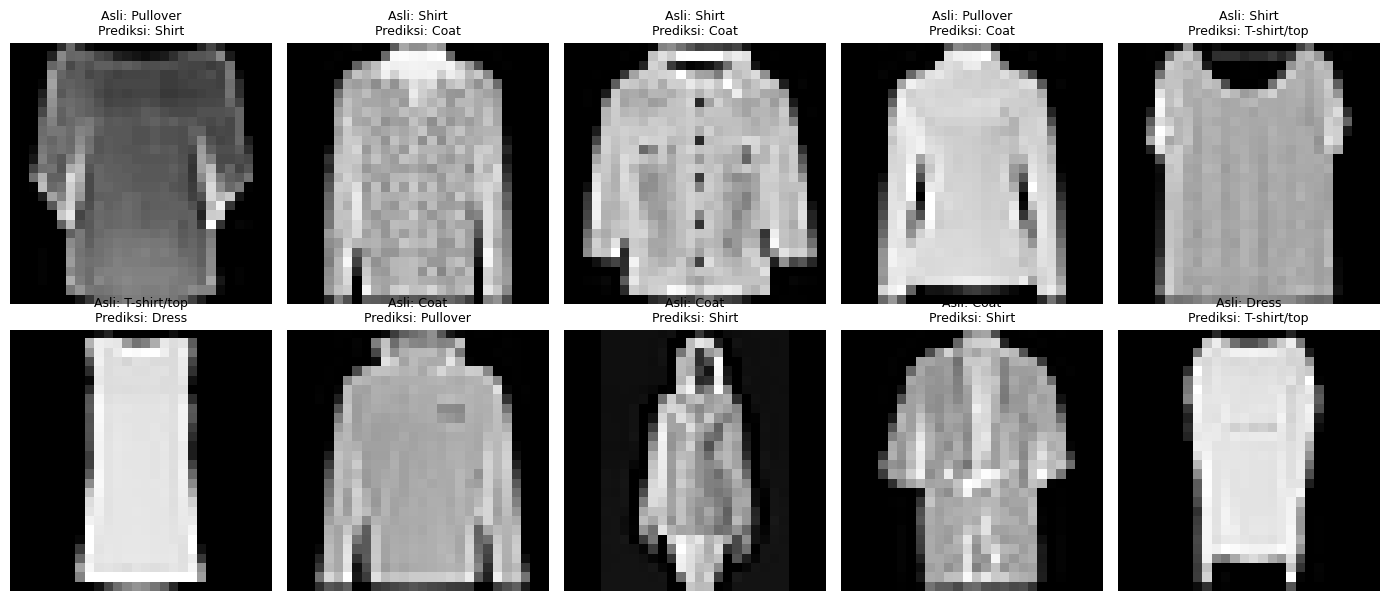

In [23]:
# Tampilkan beberapa contoh gambar yang salah diklasifikasikan oleh model terbaik,
# beserta label asli dan label prediksinya.
wrong_idx = np.where(best_pred != y_test_np)[0]
print("Jumlah salah klasifikasi:", len(wrong_idx))
fig, axes = plt.subplots(2, 5, figsize=(14, 6))
for ax, idx in zip(axes.flatten(), wrong_idx[:10]):
    ax.imshow(X_test_np[idx].reshape(28, 28), cmap="gray")
    ax.set_title(f"Asli: {class_names[y_test_np[idx]]}\nPrediksi: {class_names[best_pred[idx]]}", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

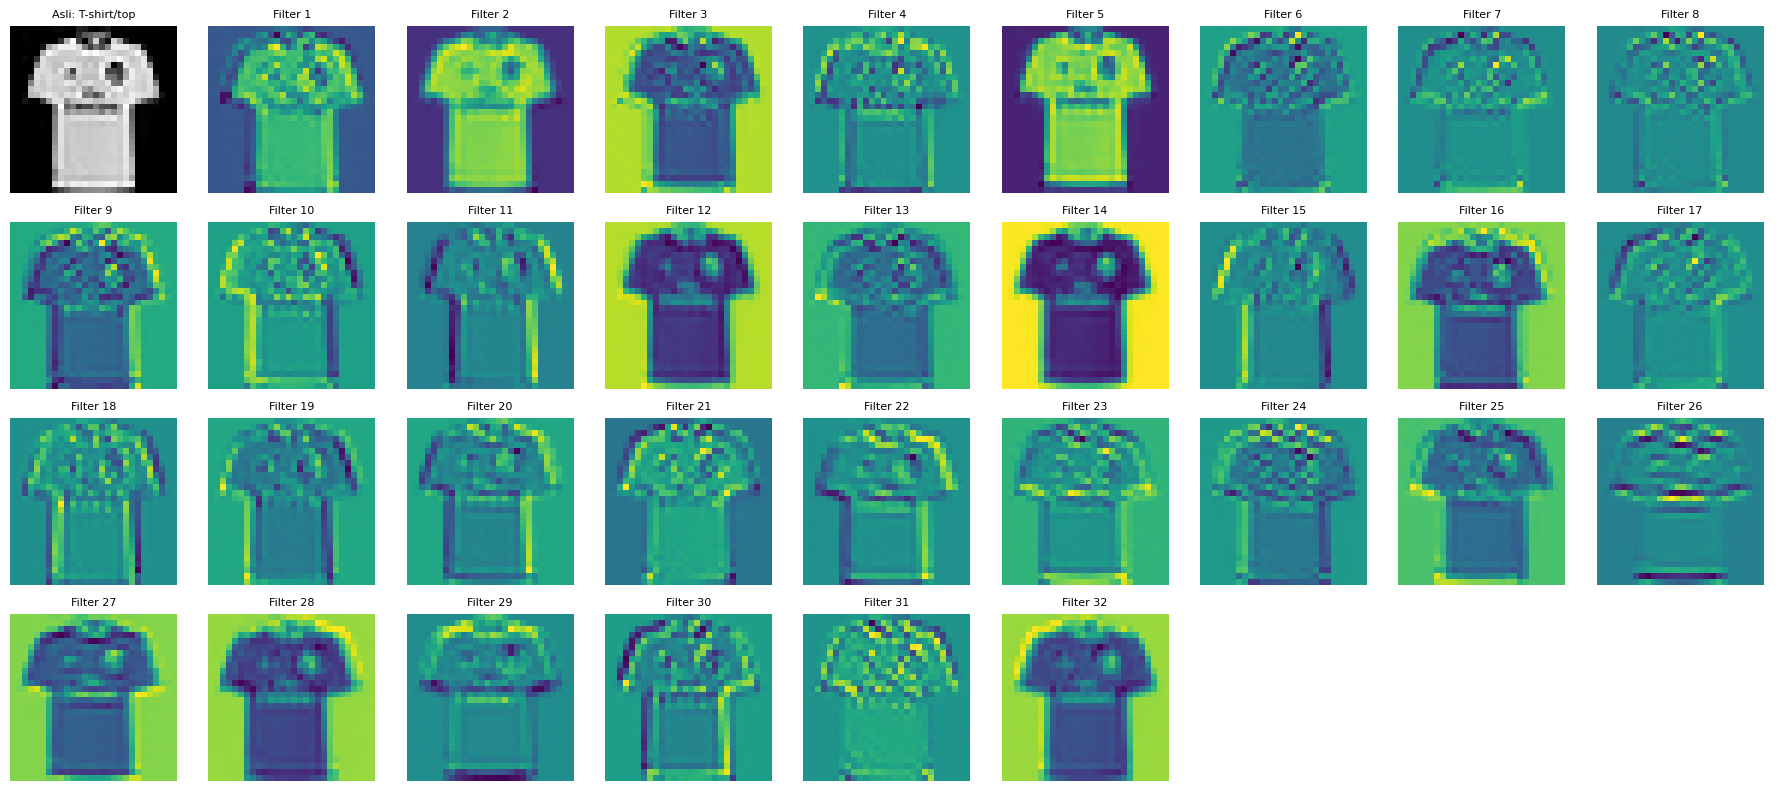

In [24]:
# Visualisasikan feature map dari layer konvolusi pertama model terbaik untuk satu gambar contoh.
# Kirim satu gambar (bentuk (1, 1, 28, 28)) ke layer konvolusi pertama saja, misalnya model.features[0](x) jika menggunakan nn.Sequential bernama features,
# lalu tampilkan setiap channel output-nya sebagai gambar (gunakan .detach().cpu().numpy()).
# Apa saja pola yang ditangkap oleh masing-masing filter?
if hasattr(best_model, "features"):
    fm_model = best_model
else:
    fm_model = cnn_bn_model
fm_model.eval()
x = X_te_t[0:1].to(device)
with torch.no_grad():
    fmap = fm_model.features[0](x).detach().cpu().numpy()[0]

fig, axes = plt.subplots(4, 9, figsize=(18, 8))
axes = axes.flatten()
axes[0].imshow(x.cpu().numpy()[0, 0], cmap="gray")
axes[0].set_title(f"Asli: {class_names[y_te_t[0].item()]}", fontsize=8)
axes[0].axis("off")
for i in range(1, len(axes)):
    if i - 1 < fmap.shape[0]:
        axes[i].imshow(fmap[i - 1], cmap="viridis")
        axes[i].set_title(f"Filter {i}", fontsize=8)
    axes[i].axis("off")
plt.tight_layout()
plt.show()

In [25]:
# Simpan bobot model terbaik ke model.pth serta ketiga model untuk keperluan Deployment Modal.
torch.save(best_model.state_dict(), "model.pth")
torch.save(ann_model.state_dict(), "ann_model.pth")
torch.save(cnn_model.state_dict(), "cnn_model.pth")
torch.save(cnn_bn_model.state_dict(), "cnn_bn_model.pth")
print("Model terbaik (", best_name, ") disimpan ke model.pth")
print("Ketiga model disimpan ke: ann_model.pth, cnn_model.pth, cnn_bn_model.pth")

Model CNN + BN + Dropout disimpan ke model.pth


# 5. Analisis

### Jelaskan secara detail hasil analisis yang didapatkan dari eksperimen yang telah dilakukan. Bandingkan performa ANN, CNN sederhana, dan CNN dengan Batch Normalization dan Dropout berdasarkan hasil evaluasi. Kaitkan perbedaan performa dengan jumlah parameter dan cara masing-masing model memproses gambar. Bahas pula pengaruh Batch Normalization dan Dropout terhadap learning curve, serta kelas-kelas yang sulit dibedakan oleh model. Pastikan analisis didasari oleh hasil eksperimen sendiri yang telah dilakukan.

Ketiga model menghasilkan 4 hasil evaluasi yang sangat bagus. CNN + BN + Dropout adalah model terbaik dengan unggul di 4 evaluasi. ANN memulukii jumlah parameter tersedikit karena seluruh parameter tersebut tersentralisasi pada lapisan Dense (fully connected). Penambahan kapasitas ini (bertambah 186.496 parameter dari ANN) berasal dari kombinasi lapisan ekstraksi fitur (Conv2D) dan lapisan klasifikasi (Dense) di bagian akhir yang membuat representasi fitur jauh lebih kaya dan akurat. Penambahan kecil ini (dari 421.642 menjadi 421.834) berasal dari parameter skala (γ) dan pergeseran (β) milik lapisan Batch Normalization, sedangkan Dropout tidak menambah parameter sama sekali. Hal ini membuktikan bahwa peningkatan performa terjadi berkat efisiensi regularisasi, bukan sekadar memperbesar ukuran model. Batch Normalization mempercepat penurunan kurva kesalahan (loss) dan memperhalus pergerakan grafik, sedangkan Dropout menyempitkan celah (gap) antara kurva pelatihan (training) dan validasi (validation). Sementara itu, kelas yang paling sulit dibedakan oleh model visi komputer adalah kelas dengan kesamaan struktur spasial, kontur tepi, atau tingkat tumpang tindih fitur visual yang tinggi.

# 6. Kesimpulan dan Saran

### Berikan kesimpulan dari eksperimen yang telah dilakukan. Saran dapat berupa rekomendasi untuk eksperimen selanjutnya, perbaikan model, atau hal-hal lain yang relevan dengan tugas ini.

CNN + BN + Dropout menjadi model terbaik dengan Accuracy 92,55% dan F1-Score (macro) 0.9246, mengungguli CNN Sederhana (Accuracy 92,25%) dan ANN (Accuracy 89,32%). erdasarkan Classification Report dan Confusion Matrix, kelas Shirt memiliki performa terendah (F1-Score 0.7581, Recall 0.6990) dan paling sering tertukar dengan T-shirt/top (167 kali), Pullover (50 kali), dan Coat (43 kali) karena kemiripan siluet atasan pada resolusi 28×28. 